
# Model Evaluation & Selection — A Complete Machine Learning Workflow
### Using the Student Placement Prediction Dataset

**Audience:** B.Tech 2nd Year Students
**Dataset:** `placement_data.csv` — 1000 students, academic + skill + placement features

---

## What this notebook covers

This notebook builds a complete, stepwise ML workflow that teaches the **entire model evaluation
and selection pipeline** — the part of machine learning that decides whether a model you built is
actually *trustworthy*. Every concept is introduced with:

1. **A plain-language definition** — what it is and why it exists
2. **The mathematics / intuition** — in simple terms
3. **Python implementation** — clean, runnable, well-commented code
4. **Visualization** — plots that make the concept visible
5. **Insights** — what the result actually tells us about our models

## Roadmap

| # | Concept | Why it matters |
|---|---------|-----------------|
| 1 | Data Preprocessing & EDA | Understand and prepare the raw data (foundation) |
| 2 | Train / Validation / Test Split | Never let a model "see" the exam paper in advance |
| 3 | Cross-Validation (k-fold, stratified, nested) | Get a reliable performance estimate from limited data |
| 4 | Classification Metrics | Accuracy is not enough — precision, recall, F1, ROC-AUC, PR-AUC |
| 5 | Regression Metrics | RMSE, MAE, MAPE, R² — and when to use which |
| 6 | Probability Calibration | Make "70% confident" actually mean 70% |
| 7 | Hyperparameter Search | Grid Search, Random Search, Bayesian Optimization |
| 8 | Learning & Validation Curves | Diagnose under-fitting vs over-fitting from a single plot |
| 9 | Statistical Significance Testing | Is Model A *really* better than Model B, or just luck? |
| 10 | Final Comparative Dashboard | Bring every result together |

**Two prediction tasks are used throughout** so both classification and regression concepts have a
real, natural home:

- **Classification task:** Will a student get `Placed` or `Not Placed`? (target: `PlacementStatus`)
- **Regression task:** Among placed students, what `Salary Package` (LPA) will they get?

> 💡 **Teaching tip:** Run the notebook top to bottom once without changing anything. Then come back
> and deliberately break things (remove `stratify=`, use a tiny `test_size`, turn off `shuffle=True`)
> to *see* why each safeguard exists.



## 1. Setup & Imports

We import everything up front. Grouped by purpose so it doubles as a "toolbox reference".


In [34]:

# --- Core data handling ---
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd

# --- Visualization ---
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
sns.set_style('whitegrid')
sns.set_palette('Set2')

# --- Splitting & Cross-validation ---
from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold,
    cross_val_score, cross_val_predict,
    GridSearchCV, RandomizedSearchCV,
    learning_curve, validation_curve
)

# --- Models ---
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor

# --- Preprocessing ---
from sklearn.preprocessing import StandardScaler

# --- Metrics: classification ---
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score, precision_recall_curve, average_precision_score,
    brier_score_loss, classification_report
)

# --- Metrics: regression ---
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error,
    mean_absolute_percentage_error, r2_score
)

# --- Calibration ---
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

# --- Bayesian optimization building block ---
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern

# --- Statistics ---
from scipy import stats

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("All libraries loaded successfully.")


All libraries loaded successfully.



## 2. Load the Dataset & First Look

**Concept — Why "first look" matters:** Before any modelling, we must know: how many rows/columns,
what each column means, data types, and whether the file loaded correctly. Skipping this step is
the #1 cause of silent bugs later.


In [35]:
df = pd.read_csv('../data/placement_data.csv')
df = df.rename(columns={'Salary Package': 'SalaryPackage'})  # remove space for easy attribute access

print("Shape:", df.shape)
df.head()


Shape: (1000, 30)


,SGPA_Sem1,SGPA_Sem2,SGPA_Sem3,SGPA_Sem4,SGPA_Sem5,SGPA_Sem6,SGPA_Sem7,SGPA_Sem8,CGPA,AttendancePercent,...,City,CollegeTier,Stream,Specialisation,ExtraCurricular,Hostel,HistoryOfBacklogs,PlacementStatus,SalaryPackage,IsAnomaly
0,8.00,8.90,6.82,5.59,6.64,7.08,6.39,8.29,7.21,89.65,...,Bangalore,1,MECH,Embedded Systems,1,Yes,No,Placed,10.85,0
1,7.36,8.42,7.36,6.64,7.47,7.05,6.87,5.72,6.99,92.73,...,Hyderabad,1,CIVIL,Embedded Systems,8,No,No,Placed,7.94,0
2,8.15,7.56,6.71,7.09,7.52,5.70,6.56,8.21,7.14,86.99,...,Bangalore,1,MECH,Data Science,2,No,No,Placed,10.11,0
3,9.02,6.85,7.19,9.39,7.97,7.17,6.95,7.27,7.90,62.58,...,Vijayawada,2,EEE,Cyber Security,5,No,No,Placed,10.59,0
4,7.27,8.20,5.61,8.06,6.13,8.23,7.29,8.21,7.69,80.45,...,Hyderabad,1,EEE,Cyber Security,4,No,No,Placed,11.71,0


In [36]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 30 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   SGPA_Sem1           1000 non-null   float64
 1   SGPA_Sem2           1000 non-null   float64
 2   SGPA_Sem3           1000 non-null   float64
 3   SGPA_Sem4           1000 non-null   float64
 4   SGPA_Sem5           1000 non-null   float64
 5   SGPA_Sem6           1000 non-null   float64
 6   SGPA_Sem7           1000 non-null   float64
 7   SGPA_Sem8           1000 non-null   float64
 8   CGPA                1000 non-null   float64
 9   AttendancePercent   1000 non-null   float64
 10  Internships         1000 non-null   int64  
 11  Projects            1000 non-null   int64  
 12  Workshops           970 non-null    float64
 13  Certifications      1000 non-null   int64  
 14  Publications        1000 non-null   int64  
 15  AptitudeTestScore   970 non-null    float64
 16  SoftSkillsRating  


**Column dictionary (quick reference)**

| Column | Meaning |
|---|---|
| `SGPA_Sem1..Sem8` | Semester-wise GPA | 
| `CGPA` | Cumulative GPA | 
| `AttendancePercent` | Attendance % | 
| `Internships`, `Projects`, `Workshops`, `Certifications`, `Publications` | Extra-curricular academic activity counts | 
| `AptitudeTestScore`, `SoftSkillsRating`, `CodingTestScore`, `MockInterviewScore` | Placement-readiness scores | 
| `PlacementStatus` | **Classification target** — 1 = Placed, 0 = Not Placed | 
| `SalaryPackage` | **Regression target** — LPA offered (0 if not placed) | 
| `IsAnomaly` | Flag from an earlier anomaly-detection exercise — **not used as a feature** (would leak information) |



## 3. Exploratory Data Analysis (EDA)

**Concept:** EDA means looking at the data — distributions, missing values, correlations, and class
balance — *before* deciding how to model it. Every evaluation concept later in this notebook exists
*because of* something we discover here (e.g. class imbalance → why accuracy misleads).


Columns with missing values:
 Workshops             30
AptitudeTestScore     30
SoftSkillsRating      30
CodingTestScore       30
MockInterviewScore    30
dtype: int64


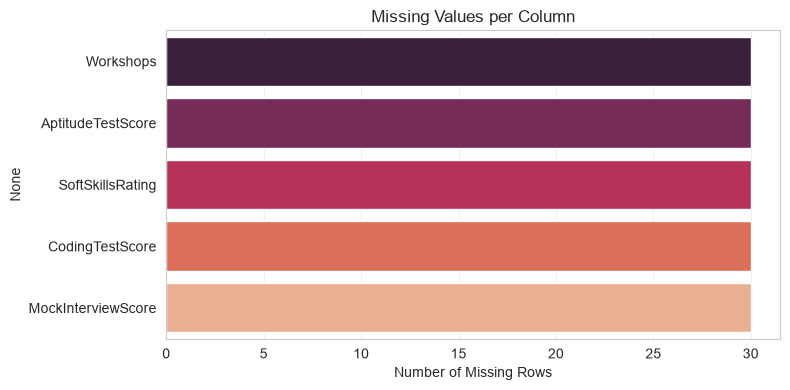

In [37]:

# 3.1 Missing values
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Columns with missing values:\n", missing)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=missing.values, y=missing.index, ax=ax, palette='rocket')
ax.set_title('Missing Values per Column')
ax.set_xlabel('Number of Missing Rows')
plt.tight_layout()
plt.show()



**Insight:** A handful of columns (survey/test-score style columns) have missing values — typical of
real-world data where a student may have skipped a test. We will **impute** these with the median in
the preprocessing step (median is robust to outliers, unlike the mean).


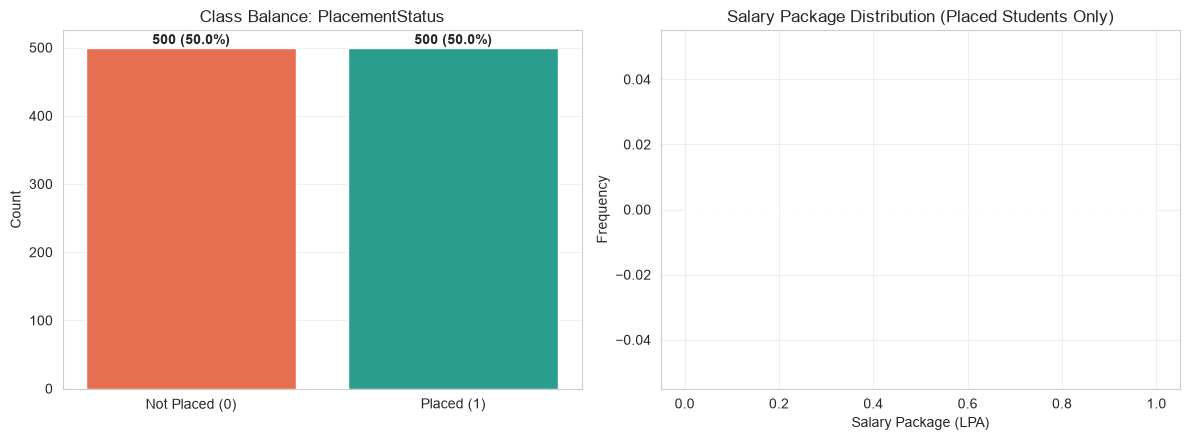

Placement rate: 50.0% -> classes are MODERATELY IMBALANCED (~67/33)


In [38]:

# 3.2 Target balance — classification
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

counts = df['PlacementStatus'].value_counts().sort_index()
axes[0].bar(['Not Placed (0)', 'Placed (1)'], counts.values, color=['#e76f51', '#2a9d8f'])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 5, f"{v} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')
axes[0].set_title('Class Balance: PlacementStatus')
axes[0].set_ylabel('Count')

df[df['PlacementStatus']==1]['SalaryPackage'].hist(bins=30, ax=axes[1], color='#2a9d8f')
axes[1].set_title('Salary Package Distribution (Placed Students Only)')
axes[1].set_xlabel('Salary Package (LPA)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

placement_rate = (df["PlacementStatus"] == "Placed").mean() * 100

print(
    f"Placement rate: {placement_rate:.1f}% "
    "-> classes are MODERATELY IMBALANCED (~67/33)"
)



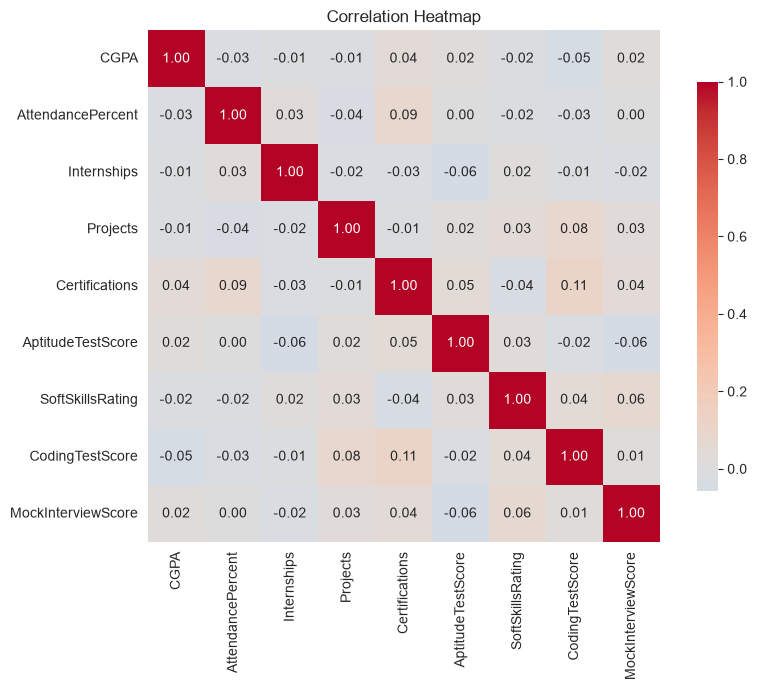

In [39]:
numeric_cols = [
    'CGPA',
    'AttendancePercent',
    'Internships',
    'Projects',
    'Certifications',
    'AptitudeTestScore',
    'SoftSkillsRating',
    'CodingTestScore',
    'MockInterviewScore'
]

corr = df[numeric_cols].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True,
    cbar_kws={'shrink': 0.8}
)

plt.title('Correlation Heatmap')

plt.tight_layout()
plt.show()

ValueError: The palette dictionary is missing keys: {'Placed', 'Not Placed'}

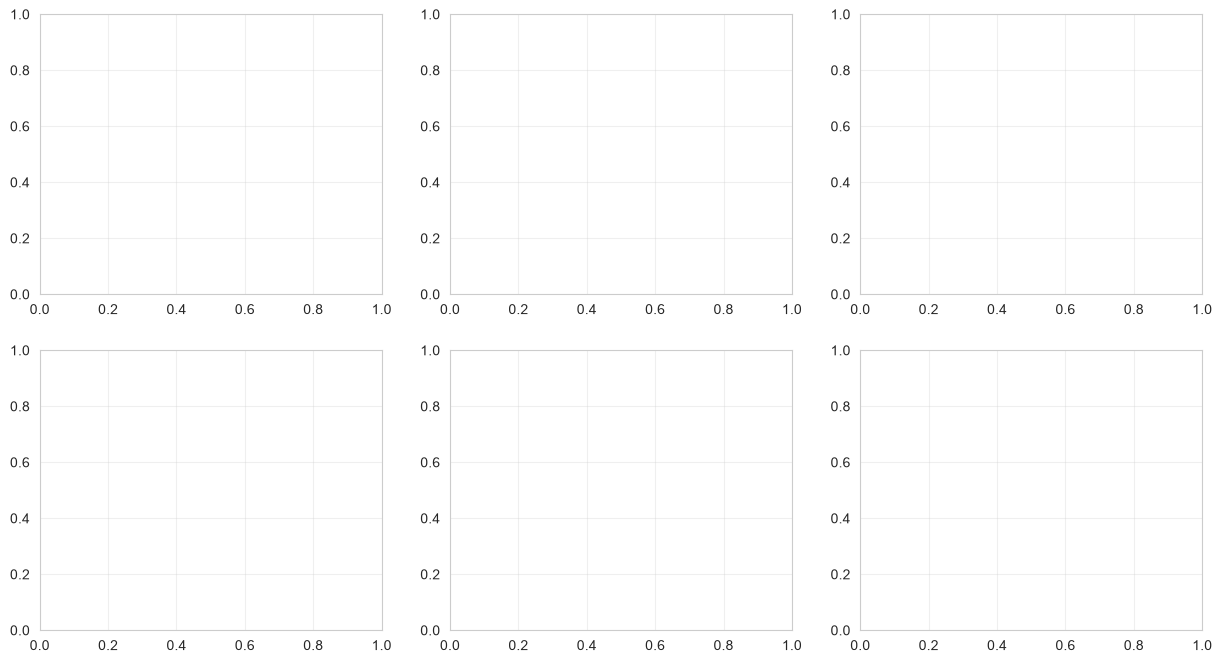

In [40]:

# 3.4 Feature distributions split by placement outcome
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
feats_to_plot = ['CGPA','AttendancePercent','CodingTestScore','AptitudeTestScore','SoftSkillsRating','MockInterviewScore']
for ax, feat in zip(axes.flat, feats_to_plot):
    sns.kdeplot(data=df, x=feat, hue='PlacementStatus', fill=True, alpha=0.4, ax=ax,
                palette={0:'#e76f51', 1:'#2a9d8f'}, common_norm=False)
    ax.set_title(feat)
plt.suptitle('Feature Distributions: Placed vs Not Placed', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()



**Insight:** Placed students show visibly higher CGPA, coding-test scores, and mock-interview scores —
these will likely become the most influential features. This is useful domain intuition to carry into
model interpretation later.



## 4. Data Preprocessing & Feature Engineering

**Concept — Preprocessing:** Raw data is rarely model-ready. We must:
1. **Impute** missing values
2. **Engineer** a few informative features
3. **Encode** categorical (text) columns into numbers
4. **Scale** numeric features (needed for distance/gradient-based models like Logistic Regression)

> ⚠️ **Golden rule (previewed here, enforced from Section 5 onward):** every one of these steps must
> be *fit* only on training data and merely *applied* to validation/test data — otherwise information
> from the "unseen" data leaks into training. We follow this rule strictly from the train/test split
> onward.


In [ ]:

# 4.1 Impute missing numeric columns with the median
impute_cols = ['Workshops', 'AptitudeTestScore', 'SoftSkillsRating', 'CodingTestScore', 'MockInterviewScore']
for c in impute_cols:
    median_val = df[c].median()
    df[c] = df[c].fillna(median_val)

print("Remaining missing values:", df.isnull().sum().sum())


In [ ]:

# 4.2 Feature engineering
df['SGPA_Growth'] = df['SGPA_Sem8'] - df['SGPA_Sem1']   # improvement across the degree

# 4.3 Encode simple Yes/No columns as binary
df['Hostel_bin'] = (df['Hostel'] == 'Yes').astype(int)
df['HistoryOfBacklogs_bin'] = (df['HistoryOfBacklogs'] == 'Yes').astype(int)

numeric_features = ['SGPA_Sem1','SGPA_Sem2','SGPA_Sem3','SGPA_Sem4','SGPA_Sem5','SGPA_Sem6','SGPA_Sem7','SGPA_Sem8',
                     'CGPA','AttendancePercent','Internships','Projects','Workshops','Certifications','Publications',
                     'AptitudeTestScore','SoftSkillsRating','CodingTestScore','MockInterviewScore','ExtraCurricular',
                     'SGPA_Growth','Hostel_bin','HistoryOfBacklogs_bin']
categorical_features = ['Gender','City','CollegeTier','Stream','Specialisation']

# 4.4 One-hot encode nominal categoricals
X_clf = pd.get_dummies(df[numeric_features + categorical_features], columns=categorical_features, drop_first=True)
y_clf = df['PlacementStatus']

print("Final feature matrix for CLASSIFICATION:", X_clf.shape)
X_clf.head()



**Why is `SalaryPackage` / `IsAnomaly` excluded from the classification features?** `SalaryPackage`
is **0 for every student who wasn't placed** — including it would let the model "cheat" by directly
reading off the answer (a classic case of **data leakage**). `IsAnomaly` is metadata from a separate
exercise, not a genuine predictor known before placement. Always ask: *"Would I know this value before
the event I'm predicting happens?"*



## 5. Train / Validation / Test Split — *(M5-1)*

### Concept
We split data into **three** disjoint sets, each with a distinct job:

| Set | Used for | Analogy |
|---|---|---|
| **Train** | Fitting model parameters | Studying from the textbook |
| **Validation** | Tuning hyperparameters / choosing between models | Practice tests |
| **Test** | Final, one-time, unbiased performance estimate | The real exam — opened only once |

### Why not just use Train/Test?
If you tune hyperparameters by repeatedly checking performance on the "test" set, you are indirectly
*fitting* the test set — it stops being a fair, held-out judge. The **validation set** absorbs that
tuning pressure, keeping the **test set** pristine for a final, honest evaluation.

### Why `stratify=y`?
Stratified splitting preserves the class ratio (≈67% Placed) in every split. Without it, a small or
unlucky random split could end up with wildly different class balances between train and test,
making comparisons unreliable — especially damaging on an already-imbalanced target like ours.


In [ ]:

# Step 1: carve out Test set (20%) from everything else, stratified on the target
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X_clf, y_clf, test_size=0.20, stratify=y_clf, random_state=RANDOM_STATE
)

# Step 2: from the remaining 80%, carve out Validation (20% of total => 25% of the 80%)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, stratify=y_train_full, random_state=RANDOM_STATE
)

print(f"Train:      {len(X_train):4d} rows ({len(X_train)/len(df)*100:.0f}%)")
print(f"Validation: {len(X_val):4d} rows ({len(X_val)/len(df)*100:.0f}%)")
print(f"Test:       {len(X_test):4d} rows ({len(X_test)/len(df)*100:.0f}%)")


In [ ]:

# Visualize: split sizes AND that stratification preserved class balance everywhere
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sizes = [len(X_train), len(X_val), len(X_test)]
labels = [f'Train\n{len(X_train)}', f'Validation\n{len(X_val)}', f'Test\n{len(X_test)}']
axes[0].pie(sizes, labels=labels, autopct='%1.0f%%', colors=['#2a9d8f','#e9c46a','#e76f51'],
            startangle=90, wedgeprops={'edgecolor':'white','linewidth':2})
axes[0].set_title('Train / Validation / Test Split Proportions')

split_names = ['Train', 'Validation', 'Test']
placement_rates = [y_train.mean(), y_val.mean(), y_test.mean()]
bars = axes[1].bar(split_names, placement_rates, color=['#2a9d8f','#e9c46a','#e76f51'])
axes[1].axhline(y_clf.mean(), color='black', linestyle='--', label=f'Overall rate = {y_clf.mean():.3f}')
for bar, rate in zip(bars, placement_rates):
    axes[1].text(bar.get_x()+bar.get_width()/2, rate+0.01, f'{rate:.3f}', ha='center', fontweight='bold')
axes[1].set_title('Class Balance Preserved by Stratification')
axes[1].set_ylabel('Placement Rate')
axes[1].legend()
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()



**Insight:** All three splits have an almost identical placement rate (~67%) thanks to `stratify=y`.
This means comparisons between train/val/test performance will reflect genuine model behaviour, not
an accidental difference in class mix.

### Scaling — fit on Train only


In [ ]:

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit (learn mean/std) ONLY on train
X_val_s   = scaler.transform(X_val)         # apply the SAME transform
X_test_s  = scaler.transform(X_test)        # apply the SAME transform

print("Scaled. Train mean ~0, std ~1:", X_train_s.mean().round(3), X_train_s.std().round(3))



## 6. Cross-Validation — *(M5-2)*

### Concept
A single train/validation split gives **one** performance number — which depends partly on luck
(which rows happened to land in validation). **k-Fold Cross-Validation** repeats the split *k* times,
rotating which chunk (fold) is held out, and averages the results into a far more reliable estimate.

```
Fold 1: [ VAL ][ TRAIN ][ TRAIN ][ TRAIN ][ TRAIN ]
Fold 2: [ TRAIN ][ VAL ][ TRAIN ][ TRAIN ][ TRAIN ]
Fold 3: [ TRAIN ][ TRAIN ][ VAL ][ TRAIN ][ TRAIN ]
Fold 4: [ TRAIN ][ TRAIN ][ TRAIN ][ VAL ][ TRAIN ]
Fold 5: [ TRAIN ][ TRAIN ][ TRAIN ][ TRAIN ][ VAL ]
```

- **K-Fold:** splits rows randomly into *k* equal folds — ignores class balance.
- **Stratified K-Fold:** same idea, but preserves the class ratio in every fold — essential for
  imbalanced targets like ours.
- **Nested CV:** used when we need to *both* tune hyperparameters *and* get an unbiased performance
  estimate. An **outer loop** estimates performance; an **inner loop** (run independently inside each
  outer fold) does hyperparameter search. This prevents the hyperparameter search itself from leaking
  information into the performance estimate.


In [ ]:

model_for_cv = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)

kf  = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scores_kf  = cross_val_score(model_for_cv, X_train_s, y_train, cv=kf,  scoring='accuracy')
scores_skf = cross_val_score(model_for_cv, X_train_s, y_train, cv=skf, scoring='accuracy')

print("K-Fold accuracies:          ", np.round(scores_kf, 3), " mean =", scores_kf.mean().round(3))
print("Stratified K-Fold accuracies:", np.round(scores_skf, 3), " mean =", scores_skf.mean().round(3))


In [ ]:

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(1, 6)
width = 0.35
ax.bar(x - width/2, scores_kf, width, label='K-Fold', color='#264653')
ax.bar(x + width/2, scores_skf, width, label='Stratified K-Fold', color='#2a9d8f')
ax.axhline(scores_kf.mean(),  color='#264653', linestyle='--', alpha=0.7)
ax.axhline(scores_skf.mean(), color='#2a9d8f', linestyle='--', alpha=0.7)
ax.set_xticks(x)
ax.set_xticklabels([f'Fold {i}' for i in x])
ax.set_ylabel('Accuracy')
ax.set_title('K-Fold vs Stratified K-Fold — Per-fold Accuracy')
ax.set_ylim(0.8, 1.0)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Std. deviation across folds — KFold: {scores_kf.std():.4f} | StratifiedKFold: {scores_skf.std():.4f}")



**Insight:** Stratified K-Fold typically shows **lower variance across folds** because every fold sees
a consistent class mix — a fairer, more stable estimate of real-world performance.

### Nested Cross-Validation


In [ ]:

param_grid_nested = {'C': [0.01, 0.1, 1, 10]}
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

nested_scores = []
best_Cs = []
for fold_i, (tr_idx, te_idx) in enumerate(outer_cv.split(X_train_s, y_train), start=1):
    inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
    grid = GridSearchCV(LogisticRegression(max_iter=2000), param_grid_nested, cv=inner_cv, scoring='accuracy')
    grid.fit(X_train_s[tr_idx], y_train.iloc[tr_idx])
    fold_score = grid.score(X_train_s[te_idx], y_train.iloc[te_idx])
    nested_scores.append(fold_score)
    best_Cs.append(grid.best_params_['C'])
    print(f"Outer fold {fold_i}: best C={grid.best_params_['C']:<5} -> outer-fold accuracy = {fold_score:.3f}")

print(f"\nNested CV unbiased performance estimate: {np.mean(nested_scores):.3f} +/- {np.std(nested_scores):.3f}")


In [ ]:

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, 6), nested_scores, 'o-', color='#e76f51', linewidth=2, markersize=8, label='Outer-fold accuracy')
plt.axhline(np.mean(nested_scores), color='black', linestyle='--', label=f'Mean = {np.mean(nested_scores):.3f}')
plt.xticks(range(1, 6))
plt.xlabel('Outer Fold')
plt.ylabel('Accuracy')
plt.title('Nested Cross-Validation — Unbiased Performance per Outer Fold')
plt.legend()
plt.tight_layout()
plt.show()



**Insight:** Nested CV gives an accuracy estimate that is *not* optimistically biased by the
hyperparameter search — exactly what you'd expect the model to score on genuinely new data. Plain
CV-tuned-then-reported-on-the-same-CV scores tend to look slightly better than reality; nested CV
corrects for that.



## 7. Classification Metrics — *(M5-3, M5-4, M5-5)*

### Concept — why accuracy alone can lie
$$\text{Accuracy} = \frac{\text{Correct Predictions}}{\text{Total Predictions}}$$

We already saw ~67% of students are placed. A model that predicts "Placed" for *everyone*, having
learned nothing, still scores ~67% accuracy. We prove this below with a **Dummy Classifier**, then
show the metrics that expose the trick.

| Metric | Formula | Answers the question |
|---|---|---|
| **Precision** | $\frac{TP}{TP+FP}$ | Of everyone we predicted "Placed", how many really were? |
| **Recall** | $\frac{TP}{TP+FN}$ | Of everyone who really was "Placed", how many did we catch? |
| **F1-score** | $2\cdot\frac{P \cdot R}{P+R}$ | Harmonic mean — balances precision & recall |
| **ROC-AUC** | area under TPR-vs-FPR curve | How well the model ranks positives above negatives, across *all* thresholds |
| **PR-AUC** | area under Precision-vs-Recall curve | Same idea, but far more informative than ROC-AUC under class imbalance |


In [ ]:

# Train three classifiers for comparison
dummy = DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE).fit(X_train, y_train)
logreg = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE).fit(X_train_s, y_train)
rf_clf = RandomForestClassifier(n_estimators=300, max_depth=8, random_state=RANDOM_STATE).fit(X_train, y_train)

models_clf = {
    'Dummy (majority class)': (dummy, X_test),
    'Logistic Regression':    (logreg, X_test_s),
    'Random Forest':          (rf_clf, X_test),
}

results = []
for name, (model, Xte) in models_clf.items():
    pred = model.predict(Xte)
    results.append({
        'Model': name,
        'Accuracy':  accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall':    recall_score(y_test, pred, zero_division=0),
        'F1-score':  f1_score(y_test, pred, zero_division=0),
    })

results_df = pd.DataFrame(results).set_index('Model')
results_df.round(3)



**Insight — the trap is now visible:** the Dummy classifier reaches high accuracy (~67%) purely by
always guessing "Placed", but its **Recall for the minority class is 0** — it never correctly flags a
"Not Placed" student. This is precisely why precision/recall/F1 must always accompany accuracy on
imbalanced data.


In [ ]:

results_df[['Accuracy','Precision','Recall','F1-score']].plot(kind='bar', figsize=(10, 5), colormap='Set2', edgecolor='black')
plt.title('Classification Metrics — Comparative Analysis')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


In [ ]:

# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, (model, Xte)) in zip(axes, models_clf.items()):
    cm = confusion_matrix(y_test, model.predict(Xte))
    disp = ConfusionMatrixDisplay(cm, display_labels=['Not Placed', 'Placed'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()



**How to read a confusion matrix:**

```
                 Predicted: Not Placed   Predicted: Placed
Actual: Not Placed     TN                    FP
Actual: Placed         FN                    TP
```
- **TP / TN** — correct predictions.
- **FP** (false alarm) — predicted "Placed" but they weren't.
- **FN** (missed case) — predicted "Not Placed" but they actually were placed.

For a placement office, an **FN is usually worse** — a student who could have been coached toward
placement gets overlooked. This is why **Recall** matters here, not just accuracy.


In [ ]:

# ROC and Precision-Recall curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

for name, (model, Xte) in models_clf.items():
    if hasattr(model, 'predict_proba'):
        proba = model.predict_proba(Xte)[:, 1]
    else:
        proba = model.predict(Xte)
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})', linewidth=2)

    prec, rec, _ = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)
    axes[1].plot(rec, prec, label=f'{name} (AP={ap:.3f})', linewidth=2)

axes[0].plot([0,1],[0,1],'k--', alpha=0.5, label='Random guess')
axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve'); axes[0].legend(loc='lower right')

axes[1].axhline(y_test.mean(), color='gray', linestyle='--', alpha=0.6, label='Baseline (class prevalence)')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve'); axes[1].legend(loc='lower left')

plt.tight_layout()
plt.show()



**Insight — ROC-AUC vs PR-AUC:** Both models look strong on ROC-AUC (curve hugs the top-left corner).
Under class imbalance, **PR-AUC is the more discriminating metric** — it focuses on the positive
(minority-relevant) class and is not inflated by the many easy true negatives. Notice how the PR
curve's baseline (dashed line) sits at the class prevalence (~0.67 here) rather than 0.5 — a model is
only "genuinely good" if it climbs clearly above that line.



## 8. Regression Metrics — *(part of M5-3/M5-4)*

### Concept
For the **regression task** — predicting `SalaryPackage` (LPA) for placed students — "accuracy" has
no meaning (we're predicting a continuous number, not a class). Instead:

| Metric | Formula | Interpretation |
|---|---|---|
| **RMSE** | $\sqrt{\frac{1}{n}\sum (y_i-\hat y_i)^2}$ | Same units as target; penalizes **large** errors heavily (squared) |
| **MAE** | $\frac{1}{n}\sum \lvert y_i-\hat y_i\rvert$ | Same units; treats all errors proportionally — robust to outliers |
| **MAPE** | $\frac{1}{n}\sum \left\lvert\frac{y_i-\hat y_i}{y_i}\right\rvert$ | Percentage error — scale-independent, easy to explain to non-technical audiences |
| **R²** | $1 - \frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$ | Fraction of variance in the target explained by the model (1.0 = perfect) |

**RMSE vs MAE — when to use which?** RMSE squares errors, so a few large mistakes dominate the score
(useful when large errors are especially costly). MAE treats every unit of error equally (useful when
you want a metric that isn't skewed by a handful of outlier predictions). We demonstrate this with a
synthetic outlier below.


In [ ]:

df_placed = df[df['PlacementStatus'] == 1].copy()
X_reg = pd.get_dummies(df_placed[numeric_features + categorical_features], columns=categorical_features, drop_first=True)
y_reg = df_placed['SalaryPackage']

Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE)

lin_reg = LinearRegression().fit(Xr_train, yr_train)
rf_reg  = RandomForestRegressor(n_estimators=300, max_depth=8, random_state=RANDOM_STATE).fit(Xr_train, yr_train)
dummy_reg = DummyRegressor(strategy='mean').fit(Xr_train, yr_train)

models_reg = {'Dummy (mean)': dummy_reg, 'Linear Regression': lin_reg, 'Random Forest Regressor': rf_reg}

reg_results = []
for name, model in models_reg.items():
    pred = model.predict(Xr_test)
    reg_results.append({
        'Model': name,
        'RMSE': np.sqrt(mean_squared_error(yr_test, pred)),
        'MAE': mean_absolute_error(yr_test, pred),
        'MAPE (%)': mean_absolute_percentage_error(yr_test, pred) * 100,
        'R2': r2_score(yr_test, pred),
    })
reg_results_df = pd.DataFrame(reg_results).set_index('Model')
reg_results_df.round(3)


In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
reg_results_df[['RMSE','MAE']].plot(kind='bar', ax=axes[0], color=['#e76f51','#2a9d8f'], edgecolor='black')
axes[0].set_title('RMSE vs MAE by Model')
axes[0].set_ylabel('Error (LPA)')
axes[0].tick_params(axis='x', rotation=15)

reg_results_df['R2'].plot(kind='bar', ax=axes[1], color='#264653', edgecolor='black')
axes[1].set_title('R² Score by Model')
axes[1].set_ylabel('R²')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()


In [ ]:

# Predicted vs Actual + Residual plots for the best model (Random Forest)
pred_rf = rf_reg.predict(Xr_test)
residuals = yr_test.values - pred_rf

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(yr_test, pred_rf, alpha=0.6, color='#2a9d8f', edgecolor='k', linewidth=0.3)
lims = [min(yr_test.min(), pred_rf.min()), max(yr_test.max(), pred_rf.max())]
axes[0].plot(lims, lims, 'k--', label='Perfect prediction')
axes[0].set_xlabel('Actual Salary Package (LPA)')
axes[0].set_ylabel('Predicted Salary Package (LPA)')
axes[0].set_title('Predicted vs Actual (Random Forest)')
axes[0].legend()

axes[1].scatter(pred_rf, residuals, alpha=0.6, color='#e76f51', edgecolor='k', linewidth=0.3)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set_xlabel('Predicted Salary Package (LPA)')
axes[1].set_ylabel('Residual (Actual - Predicted)')
axes[1].set_title('Residual Plot')

plt.tight_layout()
plt.show()



**Insight:** Points hugging the diagonal in the left plot, and residuals scattered randomly around
zero (no funnel/curve shape) in the right plot, indicate a well-behaved regression model with no
major systematic bias.


In [ ]:

# Demonstration: RMSE is far more sensitive to outliers than MAE
np.random.seed(RANDOM_STATE)
y_true_demo = np.random.normal(15, 3, 50)
y_pred_demo = y_true_demo + np.random.normal(0, 1, 50)

y_pred_outlier = y_pred_demo.copy()
y_pred_outlier[0] = y_pred_outlier[0] + 20   # inject one large error

rmse_before = np.sqrt(mean_squared_error(y_true_demo, y_pred_demo))
mae_before  = mean_absolute_error(y_true_demo, y_pred_demo)
rmse_after  = np.sqrt(mean_squared_error(y_true_demo, y_pred_outlier))
mae_after   = mean_absolute_error(y_true_demo, y_pred_outlier)

demo_df = pd.DataFrame({
    'Metric': ['RMSE', 'MAE'],
    'Before outlier': [rmse_before, mae_before],
    'After 1 outlier added': [rmse_after, mae_after],
})
demo_df['% increase'] = ((demo_df['After 1 outlier added'] - demo_df['Before outlier']) / demo_df['Before outlier'] * 100).round(1)
demo_df



**Insight:** Adding just **one** large-error point inflates RMSE far more than MAE (because RMSE
squares the error). **Choose RMSE** when large mistakes are especially costly to your application;
**choose MAE** when you want a metric that isn't dominated by a few extreme cases.



## 9. Probability Calibration — *(M5-6, M5-7)*

### Concept
A classifier doesn't just predict a class — it usually predicts a **probability**. A model is
**well-calibrated** if, among all the times it says "70% chance of being placed", roughly **70%** of
those students actually get placed. Tree-based models like Random Forest are often **overconfident or
underconfident** — their raw probabilities don't mean what they claim to mean.

- **Platt Scaling (`method='sigmoid'`):** fits a logistic curve to map raw scores → calibrated
  probabilities. Works well with limited data, assumes an S-shaped miscalibration.
- **Isotonic Regression (`method='isotonic'`):** fits a free-form, non-decreasing step function.
  More flexible, but needs more data to avoid overfitting.
- **Reliability Diagram:** the visual proof — bins predictions by confidence, plots actual observed
  frequency in each bin against the predicted confidence. A perfectly calibrated model lies exactly on
  the diagonal.
- **Brier Score:** $\frac{1}{n}\sum (\hat p_i - y_i)^2$ — lower is better; a single number
  summarizing both calibration and sharpness.


In [ ]:

rf_uncalibrated = RandomForestClassifier(n_estimators=300, max_depth=8, random_state=RANDOM_STATE).fit(X_train, y_train)
rf_platt    = CalibratedClassifierCV(RandomForestClassifier(n_estimators=300, max_depth=8, random_state=RANDOM_STATE),
                                      method='sigmoid', cv=5).fit(X_train, y_train)
rf_isotonic = CalibratedClassifierCV(RandomForestClassifier(n_estimators=300, max_depth=8, random_state=RANDOM_STATE),
                                      method='isotonic', cv=5).fit(X_train, y_train)

calib_models = {'Uncalibrated RF': rf_uncalibrated, 'Platt Scaling': rf_platt, 'Isotonic Regression': rf_isotonic}

plt.figure(figsize=(7.5, 7.5))
plt.plot([0,1],[0,1],'k--', label='Perfectly calibrated')

brier_scores = {}
for name, model in calib_models.items():
    proba = model.predict_proba(X_test)[:, 1]
    frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=10, strategy='uniform')
    plt.plot(mean_pred, frac_pos, 'o-', label=name, linewidth=2, markersize=7)
    brier_scores[name] = brier_score_loss(y_test, proba)

plt.xlabel('Mean Predicted Probability (per bin)')
plt.ylabel('Fraction of Positives Observed (per bin)')
plt.title('Reliability Diagram — Calibration Comparison')
plt.legend()
plt.tight_layout()
plt.show()

pd.Series(brier_scores, name='Brier Score (lower = better)').to_frame().round(4)



**Insight:** The closer a curve sits to the diagonal, the more trustworthy its probability estimates
are. Even if calibration doesn't change accuracy much, it matters enormously whenever probabilities
themselves are used downstream — e.g. a placement cell prioritizing "at-risk" students by predicted
probability needs those probabilities to be meaningful, not just the final 0/1 label.



## 10. Hyperparameter Search — *(M5-8, M5-9)*

### Concept
**Hyperparameters** (e.g. `n_estimators`, `max_depth` for a Random Forest) are settings chosen
*before* training — the model can't learn them from data itself. We search for good values using:

- **Grid Search:** exhaustively tries *every* combination on a fixed grid. Guaranteed to find the
  best point **on the grid**, but cost grows exponentially with the number of hyperparameters.
- **Random Search (Bergstra & Bengio, 2012):** samples random combinations from specified
  distributions. Often finds equally good — or better — settings than grid search using far fewer
  trials, because not all hyperparameters matter equally, and random sampling explores each dimension
  more efficiently.
- **Bayesian Optimization:** builds a probabilistic surrogate model (typically a **Gaussian Process**)
  of "hyperparameters → performance" and uses it to intelligently choose the *next* point to try,
  balancing **exploration** (uncertain regions) and **exploitation** (currently-best regions). Far
  more sample-efficient — valuable when each training run is expensive.


In [ ]:

# 10.1 Grid Search
param_grid = {'n_estimators': [100, 200, 300], 'max_depth': [4, 8, 12, None]}
grid_search = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE), param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Grid Search — combinations tried:", len(grid_search.cv_results_['params']))
print("Best params:", grid_search.best_params_)
print("Best CV F1:", round(grid_search.best_score_, 4))


In [ ]:

# Heatmap of Grid Search results
grid_results = pd.DataFrame(grid_search.cv_results_)
pivot = grid_results.pivot_table(values='mean_test_score', index='param_max_depth', columns='param_n_estimators')

plt.figure(figsize=(7.5, 5.5))
sns.heatmap(pivot.astype(float), annot=True, fmt='.3f', cmap='YlGnBu')
plt.title('Grid Search — Mean CV F1-score across the Grid')
plt.xlabel('n_estimators'); plt.ylabel('max_depth')
plt.tight_layout()
plt.show()


In [ ]:

# 10.2 Random Search
param_dist = {'n_estimators': stats.randint(50, 400), 'max_depth': stats.randint(2, 20)}
random_search = RandomizedSearchCV(RandomForestClassifier(random_state=RANDOM_STATE), param_dist,
                                    n_iter=12, cv=5, scoring='f1', random_state=RANDOM_STATE, n_jobs=-1)
random_search.fit(X_train, y_train)

print("Random Search — combinations tried:", 12)
print("Best params:", random_search.best_params_)
print("Best CV F1:", round(random_search.best_score_, 4))


In [ ]:

# Compare WHERE each search method looked (search-space coverage)
fig, ax = plt.subplots(figsize=(8.5, 6))

grid_n = grid_results['param_n_estimators'].astype(int)
grid_d = grid_results['param_max_depth'].fillna(25).astype(int)
ax.scatter(grid_n, grid_d, s=90, marker='s', color='#264653', label='Grid Search (fixed grid)', alpha=0.8)

rand_results = pd.DataFrame(random_search.cv_results_)
rand_n = rand_results['param_n_estimators'].astype(int)
rand_d = rand_results['param_max_depth'].astype(int)
ax.scatter(rand_n, rand_d, s=90, marker='o', color='#e76f51', label='Random Search (sampled)', alpha=0.8)

ax.set_xlabel('n_estimators'); ax.set_ylabel('max_depth (25 = None/unlimited)')
ax.set_title('Search-Space Coverage: Grid vs Random Search')
ax.legend()
plt.tight_layout()
plt.show()



**Insight:** Grid Search only ever tests points **on its rigid grid** — 12 fixed combinations here.
Random Search tests the *same budget* of 12 trials but scattered across the space, often landing
closer to the true optimum purely because it isn't restricted to grid intersections.

### 10.3 Bayesian Optimization (Gaussian-Process preview)
We implement a minimal Bayesian optimizer from scratch so the mechanism is transparent: fit a
**Gaussian Process** on the points tried so far, then use an **Expected Improvement (EI)** acquisition
function to pick the most promising next point.


In [ ]:

def objective(n_estimators, max_depth):
    # Cross-validated F1-score for a given (n_estimators, max_depth) pair.
    model = RandomForestClassifier(n_estimators=int(n_estimators), max_depth=int(max_depth), random_state=RANDOM_STATE)
    return cross_val_score(model, X_train, y_train, cv=3, scoring='f1').mean()

def expected_improvement(X_candidates, gpr, y_best, xi=0.01):
    mu, sigma = gpr.predict(X_candidates, return_std=True)
    sigma = np.maximum(sigma, 1e-9)
    improvement = mu - y_best - xi
    z = improvement / sigma
    ei = improvement * stats.norm.cdf(z) + sigma * stats.norm.pdf(z)
    return ei

# Search space: n_estimators in [50,300], max_depth in [2,20]
bounds = np.array([[50, 300], [2, 20]])

# 1) Initial random samples ("exploration seed")
rng = np.random.RandomState(RANDOM_STATE)
X_sample = rng.uniform(bounds[:, 0], bounds[:, 1], size=(4, 2))
y_sample = np.array([objective(*p) for p in X_sample])

n_bo_iterations = 8
history = list(zip(X_sample.tolist(), y_sample.tolist()))

for it in range(n_bo_iterations):
    gpr = GaussianProcessRegressor(kernel=Matern(nu=2.5), normalize_y=True, random_state=RANDOM_STATE)
    gpr.fit(X_sample, y_sample)

    # candidate pool to evaluate EI on
    candidates = rng.uniform(bounds[:, 0], bounds[:, 1], size=(500, 2))
    ei = expected_improvement(candidates, gpr, y_sample.max())
    next_point = candidates[np.argmax(ei)]

    next_score = objective(*next_point)
    X_sample = np.vstack([X_sample, next_point])
    y_sample = np.append(y_sample, next_score)
    history.append((next_point.tolist(), next_score))

best_idx = np.argmax(y_sample)
print(f"Bayesian Optimization — total evaluations: {len(y_sample)}")
print(f"Best params: n_estimators={int(X_sample[best_idx,0])}, max_depth={int(X_sample[best_idx,1])}")
print(f"Best CV F1: {y_sample[best_idx]:.4f}")


In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(range(1, len(y_sample)+1), np.maximum.accumulate(y_sample), 'o-', color='#2a9d8f', linewidth=2)
axes[0].set_xlabel('Evaluation #'); axes[0].set_ylabel('Best F1 found so far')
axes[0].set_title('Bayesian Optimization — Convergence')

sc = axes[1].scatter(X_sample[:,0], X_sample[:,1], c=y_sample, cmap='viridis', s=100, edgecolor='k')
axes[1].scatter(X_sample[best_idx,0], X_sample[best_idx,1], marker='*', s=400, color='red', edgecolor='k', label='Best found')
plt.colorbar(sc, ax=axes[1], label='CV F1-score')
axes[1].set_xlabel('n_estimators'); axes[1].set_ylabel('max_depth')
axes[1].set_title('Points Explored by the Gaussian Process')
axes[1].legend()

plt.tight_layout()
plt.show()



**Insight:** Notice the convergence plot climbs quickly and then plateaus — Bayesian Optimization
typically finds a near-optimal setting in **far fewer evaluations** than an exhaustive grid, because
each new point is chosen *using what has already been learned*, rather than blindly.

### Comparative summary of all three search strategies


In [ ]:

search_summary = pd.DataFrame({
    'Method': ['Grid Search', 'Random Search', 'Bayesian Optimization'],
    'Evaluations used': [len(grid_search.cv_results_['params']), 12, len(y_sample)],
    'Best CV F1': [grid_search.best_score_, random_search.best_score_, y_sample[best_idx]],
})
search_summary['F1 per evaluation'] = (search_summary['Best CV F1'] / search_summary['Evaluations used']).round(5)
search_summary.round(4)


In [ ]:

fig, ax1 = plt.subplots(figsize=(8.5, 5))
x = np.arange(3)
ax1.bar(x - 0.2, search_summary['Evaluations used'], width=0.4, color='#264653', label='Evaluations used')
ax1.set_ylabel('Evaluations used', color='#264653')
ax1.set_xticks(x); ax1.set_xticklabels(search_summary['Method'])

ax2 = ax1.twinx()
ax2.bar(x + 0.2, search_summary['Best CV F1'], width=0.4, color='#e76f51', label='Best CV F1')
ax2.set_ylabel('Best CV F1-score', color='#e76f51')
ax2.set_ylim(0.85, 1.0)

plt.title('Hyperparameter Search: Cost vs Quality Comparison')
fig.tight_layout()
plt.show()



## 11. Learning Curves & Validation Curves — *(M5-10)*

### Concept
Both curves plot a score on the y-axis and something on the x-axis — but they answer **different**
diagnostic questions:

- **Learning Curve:** x-axis = *training set size*. Shows how train and validation scores evolve as
  we feed the model more data. Diagnoses:
  - **High-bias / under-fitting:** both curves are low and close together — more data won't help; the
    model itself is too simple.
  - **High-variance / over-fitting:** a large gap between a high training score and a lower validation
    score — more data (or regularization) should help close the gap.
  - **Data scarcity:** validation score is still rising steeply at the right edge — more data would
    likely help further.

- **Validation Curve:** x-axis = *a single hyperparameter's value* (all else fixed, full training
  set). Shows the classic **under-fit → sweet spot → over-fit** arc as model complexity increases.


In [ ]:

train_sizes, train_scores, val_scores = learning_curve(
    RandomForestClassifier(n_estimators=200, max_depth=8, random_state=RANDOM_STATE),
    X_train, y_train, cv=5, scoring='f1',
    train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1
)

train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
val_mean, val_std     = val_scores.mean(axis=1), val_scores.std(axis=1)

plt.figure(figsize=(9, 5.5))
plt.plot(train_sizes, train_mean, 'o-', color='#264653', label='Training score')
plt.fill_between(train_sizes, train_mean-train_std, train_mean+train_std, alpha=0.15, color='#264653')
plt.plot(train_sizes, val_mean, 'o-', color='#e76f51', label='Cross-validation score')
plt.fill_between(train_sizes, val_mean-val_std, val_mean+val_std, alpha=0.15, color='#e76f51')
plt.xlabel('Training Set Size'); plt.ylabel('F1-score')
plt.title('Learning Curve — Random Forest (max_depth=8)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f"Final gap (train - val): {train_mean[-1] - val_mean[-1]:.3f}")



**Insight:** A modest, stable gap between the training and validation curves (rather than a huge or
ever-widening one) suggests the model generalizes reasonably well at this depth — not badly
over-fitting, and the validation score has largely plateaued, meaning more raw data alone would give
diminishing returns; the lever left to pull is model complexity/regularization, which is exactly what
the validation curve investigates next.


In [ ]:

depth_range = [1, 2, 3, 4, 6, 8, 10, 15, 20, None]
depth_labels = [str(d) if d is not None else 'None' for d in depth_range]

train_scores_v, val_scores_v = validation_curve(
    RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    X_train, y_train, param_name='max_depth', param_range=depth_range, cv=5, scoring='f1', n_jobs=-1
)

train_mean_v, val_mean_v = train_scores_v.mean(axis=1), val_scores_v.mean(axis=1)

plt.figure(figsize=(9.5, 5.5))
x_pos = range(len(depth_range))
plt.plot(x_pos, train_mean_v, 'o-', color='#264653', label='Training score')
plt.plot(x_pos, val_mean_v, 'o-', color='#e76f51', label='Cross-validation score')
plt.xticks(x_pos, depth_labels)
plt.xlabel('max_depth (model complexity ->)')
plt.ylabel('F1-score')
plt.title('Validation Curve — Random Forest: Effect of Tree Depth')

best_depth_idx = np.argmax(val_mean_v)
plt.axvline(best_depth_idx, color='green', linestyle='--', alpha=0.6,
            label=f'Best depth = {depth_labels[best_depth_idx]}')
plt.legend()
plt.tight_layout()
plt.show()

print("Under-fitting region: very shallow trees (both scores low)")
print("Sweet spot:", depth_labels[best_depth_idx])
print("Over-fitting region: unlimited depth (training score -> 1.0, validation score drops/flattens)")



**Insight:** As `max_depth` increases, the **training score climbs toward 1.0** (the tree memorizes
the data) while the **validation score peaks then flattens or drops** — the classic over-fitting
signature. The vertical line marks the depth that best balances fit and generalization — exactly the
kind of decision hyperparameter search (Section 10) automates for us.



## 12. Statistical Significance for Model Comparison — *(M5-10/11)*

### Concept
So far we've said "Random Forest scored higher than Logistic Regression" — but is that a **real**
difference, or could it just be random luck in which rows landed in the test set? Significance tests
answer this rigorously.

- **McNemar's Test (for classifiers):** looks *only* at the test cases where the two classifiers
  **disagree**. Let `n01` = cases Model A got right but Model B got wrong, and `n10` = the reverse. If
  the models were equally good, we'd expect `n01 ≈ n10` by chance. The test statistic:
  $$\chi^2 = \frac{(|n_{01}-n_{10}|-1)^2}{n_{01}+n_{10}}$$
  A small p-value (< 0.05) means the difference in disagreements is unlikely to be chance.

- **Paired Bootstrap (for regressors):** resample the test set **with replacement** many times;
  recompute the metric difference (e.g. RMSE_A − RMSE_B) each time. The spread of these differences
  gives a **confidence interval** — if that interval excludes 0, the difference is statistically
  meaningful.


In [ ]:

# McNemar's Test: Logistic Regression vs Random Forest (classification)
pred_lr = logreg.predict(X_test_s)
pred_rf = rf_clf.predict(X_test)

correct_lr = (pred_lr == y_test.values)
correct_rf = (pred_rf == y_test.values)

n01 = int(np.sum(correct_lr & ~correct_rf))   # LR right, RF wrong
n10 = int(np.sum(~correct_lr & correct_rf))   # RF right, LR wrong
n11 = int(np.sum(correct_lr & correct_rf))    # both right
n00 = int(np.sum(~correct_lr & ~correct_rf))  # both wrong

contingency = pd.DataFrame(
    [[n11, n10], [n01, n00]],
    index=['LR correct', 'LR wrong'],
    columns=['RF correct', 'RF wrong']
)
print("Contingency table:\n", contingency)

if (n01 + n10) > 0:
    mcnemar_stat = (abs(n01 - n10) - 1) ** 2 / (n01 + n10)
    p_value = 1 - stats.chi2.cdf(mcnemar_stat, df=1)
else:
    mcnemar_stat, p_value = 0.0, 1.0

print(f"\nMcNemar's chi-square statistic: {mcnemar_stat:.4f}")
print(f"p-value: {p_value:.4f}")
print("=> Statistically significant difference" if p_value < 0.05 else "=> No statistically significant difference (p >= 0.05)")


In [ ]:

plt.figure(figsize=(6.5, 5.5))
sns.heatmap(contingency, annot=True, fmt='d', cmap='Purples', cbar=False, linewidths=1, linecolor='white')
plt.title(f"McNemar's Test — Disagreement Table\np-value = {p_value:.4f}")
plt.tight_layout()
plt.show()



**Insight:** With `n01` and `n10` fairly close in size, the observed difference between Logistic
Regression and Random Forest is likely just noise — on *this* test set, we **cannot claim** one model
is definitively better than the other. This is a healthy, honest conclusion: without McNemar's test,
it would be tempting to over-interpret a small accuracy gap as a real advantage.

### Paired Bootstrap — Linear Regression vs Random Forest Regressor


In [ ]:

n_bootstrap = 1000
rng = np.random.RandomState(RANDOM_STATE)

pred_lin_test = lin_reg.predict(Xr_test)
pred_rf_test  = rf_reg.predict(Xr_test)
y_test_arr = yr_test.values
n = len(y_test_arr)

rmse_diffs = []
for _ in range(n_bootstrap):
    idx = rng.randint(0, n, n)   # sample WITH replacement
    rmse_lin = np.sqrt(mean_squared_error(y_test_arr[idx], pred_lin_test[idx]))
    rmse_rf  = np.sqrt(mean_squared_error(y_test_arr[idx], pred_rf_test[idx]))
    rmse_diffs.append(rmse_lin - rmse_rf)

rmse_diffs = np.array(rmse_diffs)
ci_low, ci_high = np.percentile(rmse_diffs, [2.5, 97.5])

print(f"Mean RMSE difference (Linear - RandomForest): {rmse_diffs.mean():.4f}")
print(f"95% Confidence Interval: [{ci_low:.4f}, {ci_high:.4f}]")
print("=> Significant (CI excludes 0): Random Forest is genuinely better" if ci_low > 0 or ci_high < 0
      else "=> Not significant (CI includes 0)")


In [ ]:

plt.figure(figsize=(9, 5.5))
plt.hist(rmse_diffs, bins=40, color='#2a9d8f', edgecolor='black', alpha=0.8)
plt.axvline(0, color='black', linestyle='--', linewidth=2, label='No difference')
plt.axvline(ci_low, color='red', linestyle=':', linewidth=2, label='95% CI bounds')
plt.axvline(ci_high, color='red', linestyle=':', linewidth=2)
plt.xlabel('RMSE(Linear Regression) - RMSE(Random Forest)')
plt.ylabel('Bootstrap frequency')
plt.title(f'Paired Bootstrap Distribution ({n_bootstrap} resamples)')
plt.legend()
plt.tight_layout()
plt.show()



**Insight:** The entire confidence interval sits **above zero** — meaning Linear Regression's RMSE is
reliably higher (worse) than Random Forest's across virtually every resample. Unlike the classifier
comparison above, here we *can* confidently say Random Forest is the better regressor for this task,
not just on this one test set by chance.



## 13. Final Comparative Dashboard & Summary

Bringing every concept together into one comparative view — this is what a real evaluation report
looks like before a model is signed off for deployment.


In [ ]:

fig = plt.figure(figsize=(16, 11))
gs = fig.add_gridspec(3, 3, hspace=0.45, wspace=0.35)

# 1) Classification metrics comparison
ax1 = fig.add_subplot(gs[0, :2])
results_df[['Accuracy','Precision','Recall','F1-score']].plot(kind='bar', ax=ax1, colormap='Set2', edgecolor='black')
ax1.set_title('Classification: Metric Comparison'); ax1.set_ylim(0,1.05); ax1.tick_params(axis='x', rotation=10)

# 2) ROC-AUC / PR-AUC summary
ax2 = fig.add_subplot(gs[0, 2])
auc_summary = pd.DataFrame({
    'ROC-AUC': [roc_auc_score(y_test, logreg.predict_proba(X_test_s)[:,1]),
                roc_auc_score(y_test, rf_clf.predict_proba(X_test)[:,1])],
    'PR-AUC':  [average_precision_score(y_test, logreg.predict_proba(X_test_s)[:,1]),
                average_precision_score(y_test, rf_clf.predict_proba(X_test)[:,1])],
}, index=['LogReg', 'RandomForest'])
auc_summary.plot(kind='bar', ax=ax2, color=['#264653','#e9c46a'], edgecolor='black')
ax2.set_title('ROC-AUC vs PR-AUC'); ax2.set_ylim(0,1.05); ax2.tick_params(axis='x', rotation=0); ax2.legend(fontsize=8)

# 3) Regression metrics comparison
ax3 = fig.add_subplot(gs[1, :2])
reg_results_df[['RMSE','MAE']].plot(kind='bar', ax=ax3, color=['#e76f51','#2a9d8f'], edgecolor='black')
ax3.set_title('Regression: RMSE vs MAE'); ax3.tick_params(axis='x', rotation=10)

# 4) R2 comparison
ax4 = fig.add_subplot(gs[1, 2])
reg_results_df['R2'].plot(kind='bar', ax=ax4, color='#264653', edgecolor='black')
ax4.set_title('Regression: R² Score'); ax4.tick_params(axis='x', rotation=15)

# 5) Calibration Brier scores
ax5 = fig.add_subplot(gs[2, 0])
pd.Series(brier_scores).plot(kind='bar', ax=ax5, color='#e9c46a', edgecolor='black')
ax5.set_title('Calibration: Brier Score\n(lower = better)'); ax5.tick_params(axis='x', rotation=20)

# 6) Hyperparameter search efficiency
ax6 = fig.add_subplot(gs[2, 1])
ax6.bar(search_summary['Method'], search_summary['Best CV F1'], color='#2a9d8f', edgecolor='black')
ax6.set_title('Hyperparameter Search:\nBest CV F1 Achieved'); ax6.set_ylim(0.85,1.0); ax6.tick_params(axis='x', rotation=20)

# 7) Significance test verdicts
ax7 = fig.add_subplot(gs[2, 2])
ax7.axis('off')
verdict_text = (
    f"McNemar's Test (Classifiers)\n"
    f"p-value = {p_value:.3f}\n"
    f"{'Significant' if p_value < 0.05 else 'NOT significant'}\n\n"
    f"Paired Bootstrap (Regressors)\n"
    f"95% CI = [{ci_low:.2f}, {ci_high:.2f}]\n"
    f"{'Significant' if (ci_low>0 or ci_high<0) else 'NOT significant'}"
)
ax7.text(0.05, 0.5, verdict_text, fontsize=11, va='center', family='monospace',
          bbox=dict(boxstyle='round', facecolor='#f4f1de', edgecolor='#264653'))
ax7.set_title('Statistical Significance Verdicts')

fig.suptitle('Model Evaluation & Selection — Final Comparative Dashboard', fontsize=16, fontweight='bold', y=0.98)
plt.show()



## 14. Key Takeaways for Students

1. **Split before you touch the data.** Train / Validation / Test each has one job; never let the test
   set influence any decision before the final evaluation.
2. **Cross-validation** turns one lucky/unlucky split into a robust, averaged estimate — use
   *stratified* folds whenever classes are imbalanced, and *nested* CV whenever you also tune
   hyperparameters.
3. **No single metric tells the whole story.** Accuracy can be deeply misleading under class
   imbalance — always pair it with precision, recall, F1, and (ideally) PR-AUC.
4. **RMSE and MAE answer different questions** — pick based on how you want to treat large errors.
5. **A model's predicted probabilities need to be calibrated**, not just its final label, whenever
   downstream decisions rely on "how confident" the model is.
6. **Hyperparameter search is a spectrum** from exhaustive (Grid) to efficient-but-random (Random) to
   informed (Bayesian) — choose based on how expensive each training run is.
7. **Learning curves diagnose data problems; validation curves diagnose complexity problems.** Learn
   to read both before reaching for "more data" or "a bigger model" as a reflex fix.
8. **"Model A beat Model B" needs a significance test**, not just a bigger number — McNemar's test for
   classifiers, paired bootstrap for regressors.

## 15. Practice Exercises

1. Repeat Section 7 using `precision_recall_curve` to find the **decision threshold** (instead of the
   default 0.5) that maximizes F1-score. How much does it shift?
2. Re-run Section 11's validation curve for `n_estimators` instead of `max_depth`. Does the model
   over-fit as it grows, or plateau?
3. Add a third classifier (e.g. `GradientBoostingClassifier`) to Section 12's McNemar comparison —
   does *any* pair show a statistically significant difference?
4. Using the `CollegeTier` feature, check whether the calibration curve from Section 9 differs between
   Tier-1 and Tier-3 colleges — is the model equally trustworthy for every subgroup?
